<div style="background-color: #0B1F3A; padding: 25px; border-radius: 10px;">

<h1 style="color: white; text-align: center;">
    Home Credit Default
</h1>

<p style="color: #B8D8F0; text-align: center; font-size: 18px;">
    Prédiction de la capacité d'un demandeur à rembourser son prêt
</p>

<p style="color: #9e6dad; text-align: center; font-size: 18px;">
    Anna ATCHOU, Ingénieure Statisticienne Economiste
</p>
</div>

# Business Understanding

## Context
Credit risk assessment is a key activity for financial institutions. Before granting a loan, banks need to evaluate the likelihood that a borrower will fail to meet their repayment obligations.

The objective of this project is to develop statistical and machine learning models to predict loan default risk using applicants' socio-economic characteristics, financial information and historical credit data.

The project also aims to identify the main factors associated with default risk and provide insights that could support credit decision-making.

## Problem Statement

Predict, for each applicant, the probability of experiencing repayment difficulties.

- **Problem type:** Supervised binary classification
- **Target variable:** `TARGET` (1 = the client experienced payment difficulties, 0 = normal repayment)

## Methodology

1. Configuration and reproducibility
2. Exploratory Data Analysis (EDA)
3. Data cleaning and feature engineering
4. Stratified cross-validation and baseline model
5. Boosting models (LightGBM, XGBoost, CatBoost) and hyperparameter optimization
6. Model ensembling
7. Evaluation, probability calibration, and threshold selection
8. Model interpretation (SHAP) and final deliverable.



# 1.Configuration

In [23]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import joblib
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


from src.config import CFG, SEED, TARGET, ID_COL, PATHS, set_seed, load_data, sanity_checks

set_seed()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


def save_fig(name):
    plt.tight_layout()
    plt.savefig(PATHS["figures"] / name, bbox_inches="tight")
    plt.show()

# 2. Chargement de la base et premier aperçu

In [2]:
train, test = load_data()
sanity_checks(train, test)

print(f"Train : {train.shape[0]:,} lignes x {train.shape[1]} colonnes")
print(f"Test  : {test.shape[0]:,} lignes x {test.shape[1]} colonnes")
print("Colonnes du train absentes du test :", sorted(set(train.columns) - set(test.columns)))
display(train.head())

20:32:30 | INFO | Train : (307511, 122) | Test : (48744, 121)
20:32:34 | INFO | Mémoire : 536.7 Mo -> 379.8 Mo
20:32:34 | INFO | Mémoire : 84.7 Mo -> 60.2 Mo
20:32:35 | INFO | Taux de défaut : 8.07 % | contrôles OK


Train : 307,511 lignes x 122 colonnes
Test  : 48,744 lignes x 121 colonnes
Colonnes du train absentes du test : ['TARGET']


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,"202,500.0000","406,597.5000","24,700.5000","351,000.0000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0188,-9461,-637,"-3,648.0000",-2120,NaN,1,1,0,1,1,0,Laborers,1.0000,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.0830,0.2629,0.1394,0.0247,0.0369,0.9722,0.6192,0.0143,0.0000,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.0220,0.0198,0.0000,0.0000,0.0250,0.0369,0.9722,0.6243,0.0144,0.0000,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.0000,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0000,2.0000,2.0000,2.0000,"-1,134.0000",0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000
1,100003,0,Cash loans,F,N,N,0,"270,000.0000","1,293,502.5000","35,698.5000","1,129,500.0000",Family,State servant,Higher education,Married,House / apartment,0.0035,-16765,-1188,"-1,186.0000",-291,NaN,1,1,0,1,1,0,Core staff,2.0000,1,1,MONDAY,11,0,0,0,0,0,0,School,0.3113,0.6222,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.0800,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.0790,0.0554,0.0000,0.0000,0.0968,0.0529,0.9851,0.7987,0.0608,0.0800,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.0100,reg oper account,block of flats,0.0714,Block,No,1.0000,0.0000,1.0000,0.0000,-828.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,100004,0,Revolving loans,M,Y,Y,0,"67,500.0000","135,000.0000","6,750.0000","135,000.0000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0100,-19046,-225,"-4,260.0000",-2531,26.0000,1,1,1,1,1,0,Laborers,1.0000

La base d'étude (train), comporte 307511 observatons et 122 variables.La variable cibleiciest nommé Target(elle est celle qui apparait dans train et non ). Nous allons essayer donc de plus compendre la base.

In [7]:
train.columns

Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY',
       ...
       'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20',
       'FLAG_DOCUMENT_21', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
       'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
       'AMT_REQ_CREDIT_BUREAU_YEAR'],
      dtype='object', length=122)

$$
\begin{array}{|l|l|}
\hline
\textbf{Variable} & \textbf{Signification} \\
\hline
\texttt{TARGET} & \text{1 = difficultés de paiement, 0 = autres cas} \\
\hline
\texttt{NAME\_CONTRACT\_TYPE} & \text{Type de prêt (classique ou renouvelable)} \\
\hline
\texttt{AMT\_INCOME\_TOTAL} & \text{Revenu total du client} \\
\hline
\texttt{AMT\_CREDIT} & \text{Montant du crédit demandé} \\
\hline
\texttt{AMT\_ANNUITY} & \text{Montant de l'annuité (remboursement périodique)} \\
\hline
\texttt{AMT\_GOODS\_PRICE} & \text{Prix du bien financé par le prêt} \\
\hline
\texttt{DAYS\_BIRTH} & \text{Âge en jours à la demande } \\
\hline
\texttt{DAYS\_EMPLOYED} & \text{Ancienneté dans l'emploi en jours } \\
\hline
\texttt{EXT\_SOURCE\_1/2/3} & \text{Scores normalisés issus de sources externes} \\
\hline
\texttt{NAME\_EDUCATION\_TYPE} & \text{Niveau d'études} \\
\hline
\texttt{NAME\_INCOME\_TYPE} & \text{Type de revenu} \\
\hline
\texttt{NAME\_FAMILY\_STATUS} & \text{Situation familiale} \\
\hline
\texttt{OCCUPATION\_TYPE} & \text{Profession} \\
\hline
\texttt{REGION\_RATING\_CLIENT} & \text{Note de la région du client (1, 2 ou 3)} \\
\hline
\texttt{OBS\_30\_CNT\_SOCIAL\_CIRCLE} & \text{Proches observés dans l'entourage social} \\
\hline
\texttt{DEF\_30\_CNT\_SOCIAL\_CIRCLE} & \text{Proches en défaut de plus de 30 jours} \\
\hline
\texttt{AMT\_REQ\_CREDIT\_BUREAU\_}\ast & \text{Demandes de renseignements au bureau de crédit} \\
\hline
\end{array}
$$

In [8]:
cat_cols = train.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in train.select_dtypes(include="number").columns if c not in (TARGET, ID_COL)]
print(f"{len(num_cols)} variables numériques, {len(cat_cols)} variables catégorielles")

print("\nCardinalité des variables catégorielles :")
display(train[cat_cols].nunique().sort_values(ascending=False).to_frame("n_modalités"))

# variables binaires encodées en 0/1 (souvent des indicateurs FLAG_*)
binary_cols = [c for c in num_cols if train[c].dropna().nunique() == 2]
print(f"\n{len(binary_cols)} variables numériques binaires, dont {sum(c.startswith('FLAG_') for c in binary_cols)} FLAG_*")

104 variables numériques, 16 variables catégorielles

Cardinalité des variables catégorielles :


,n_modalités
ORGANIZATION_TYPE,58
OCCUPATION_TYPE,18
NAME_INCOME_TYPE,8
NAME_TYPE_SUITE,7
WEEKDAY_APPR_PROCESS_START,7
WALLSMATERIAL_MODE,7
NAME_FAMILY_STATUS,6
NAME_HOUSING_TYPE,6
NAME_EDUCATION_TYPE,5
FONDKAPREMONT_MODE,4



32 variables numériques binaires, dont 26 FLAG_*


# 3. Vérification et traitement des valeurs manquantes

In [9]:
train.isnull().sum().to_frame().rename(columns={0:"Total Nb. of Missing Values"})

,Total Nb. of Missing Values
SK_ID_CURR,0
TARGET,0
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
FLAG_OWN_CAR,0
...,...
AMT_REQ_CREDIT_BUREAU_DAY,41519
AMT_REQ_CREDIT_BUREAU_WEEK,41519
AMT_REQ_CREDIT_BUREAU_MON,41519
AMT_REQ_CREDIT_BUREAU_QRT,41519


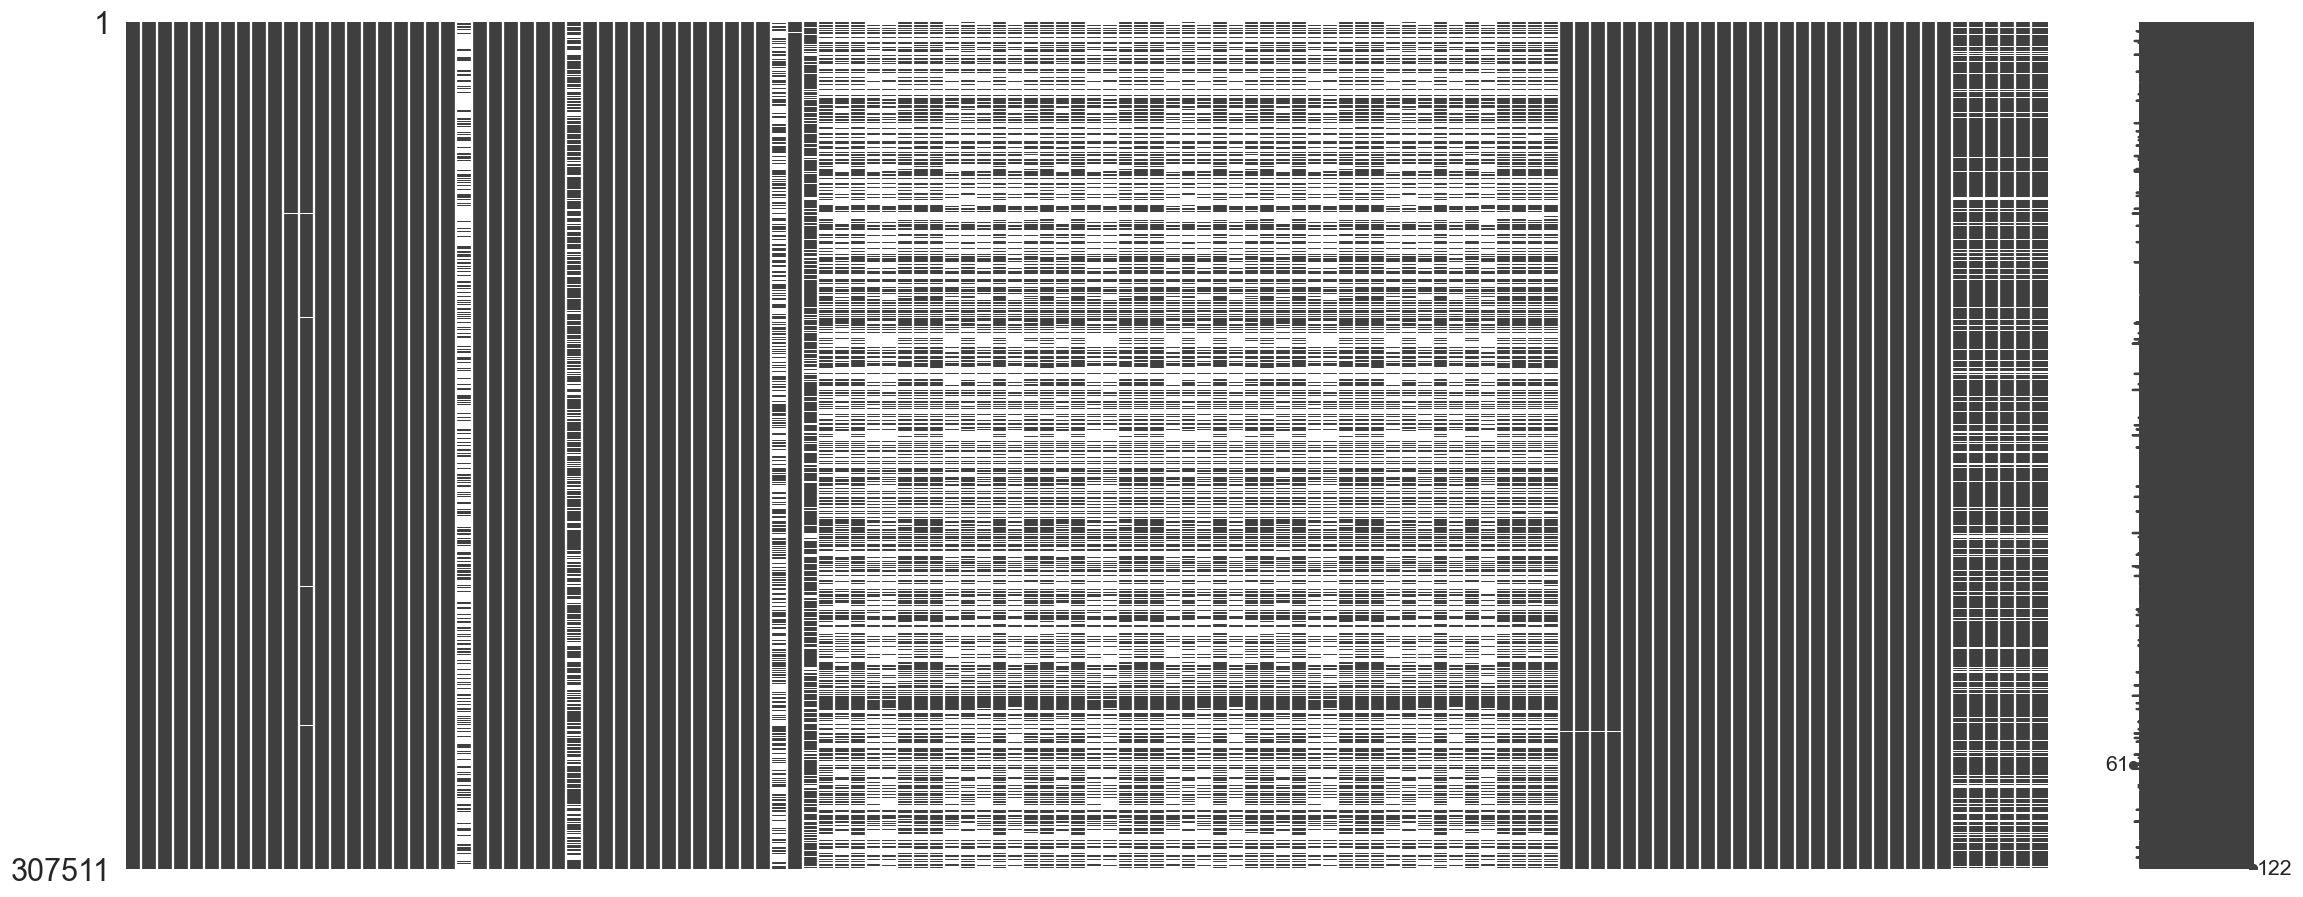

In [14]:
msno.matrix(train);

67 colonnes avec des valeurs manquantes sur 122
41 colonnes avec plus de 50 % de manquants
50 colonnes avec plus de 30 % de manquants


,pct_manquant
COMMONAREA_MEDI,69.8723
COMMONAREA_AVG,69.8723
COMMONAREA_MODE,69.8723
NONLIVINGAPARTMENTS_MODE,69.4330
NONLIVINGAPARTMENTS_AVG,69.4330
NONLIVINGAPARTMENTS_MEDI,69.4330
FONDKAPREMONT_MODE,68.3862
LIVINGAPARTMENTS_MODE,68.3550
LIVINGAPARTMENTS_AVG,68.3550
LIVINGAPARTMENTS_MEDI,68.3550


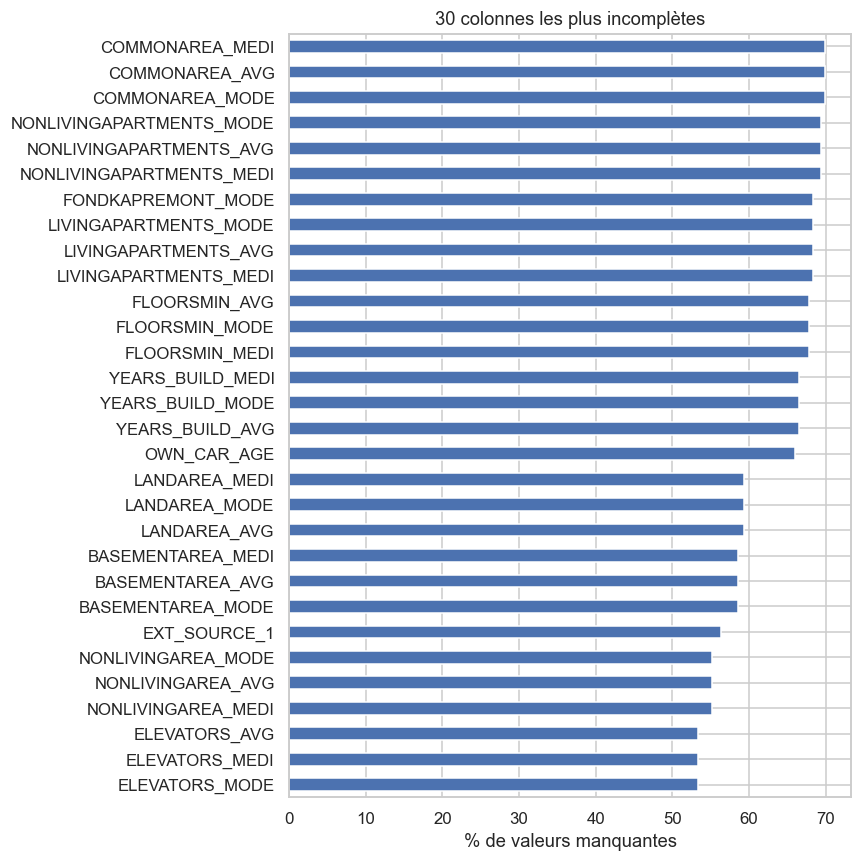

In [10]:
missing = train.isna().mean().mul(100).rename("pct_manquant").sort_values(ascending=False)
missing = missing[missing > 0]
print(f"{len(missing)} colonnes avec des valeurs manquantes sur {train.shape[1]}")
print(f"{(missing > 50).sum()} colonnes avec plus de 50 % de manquants")
print(f"{(missing > 30).sum()} colonnes avec plus de 30 % de manquants")
display(missing.head(30).to_frame())

fig, ax = plt.subplots(figsize=(8, 8))
missing.head(30).sort_values().plot.barh(ax=ax)
ax.set_xlabel("% de valeurs manquantes")
ax.set_title("30 colonnes les plus incomplètes")
save_fig("02_missing_values.png")

Dans notre jeu de donner on remarque la présence de plusieurs valeurs manquantes. Nous allons procéder à une verification des distributions, des liens avec lavariables cible et utiliser le critère AUC-ROC pour pouvoir faire le choix de la méthode et des variables à imputer.

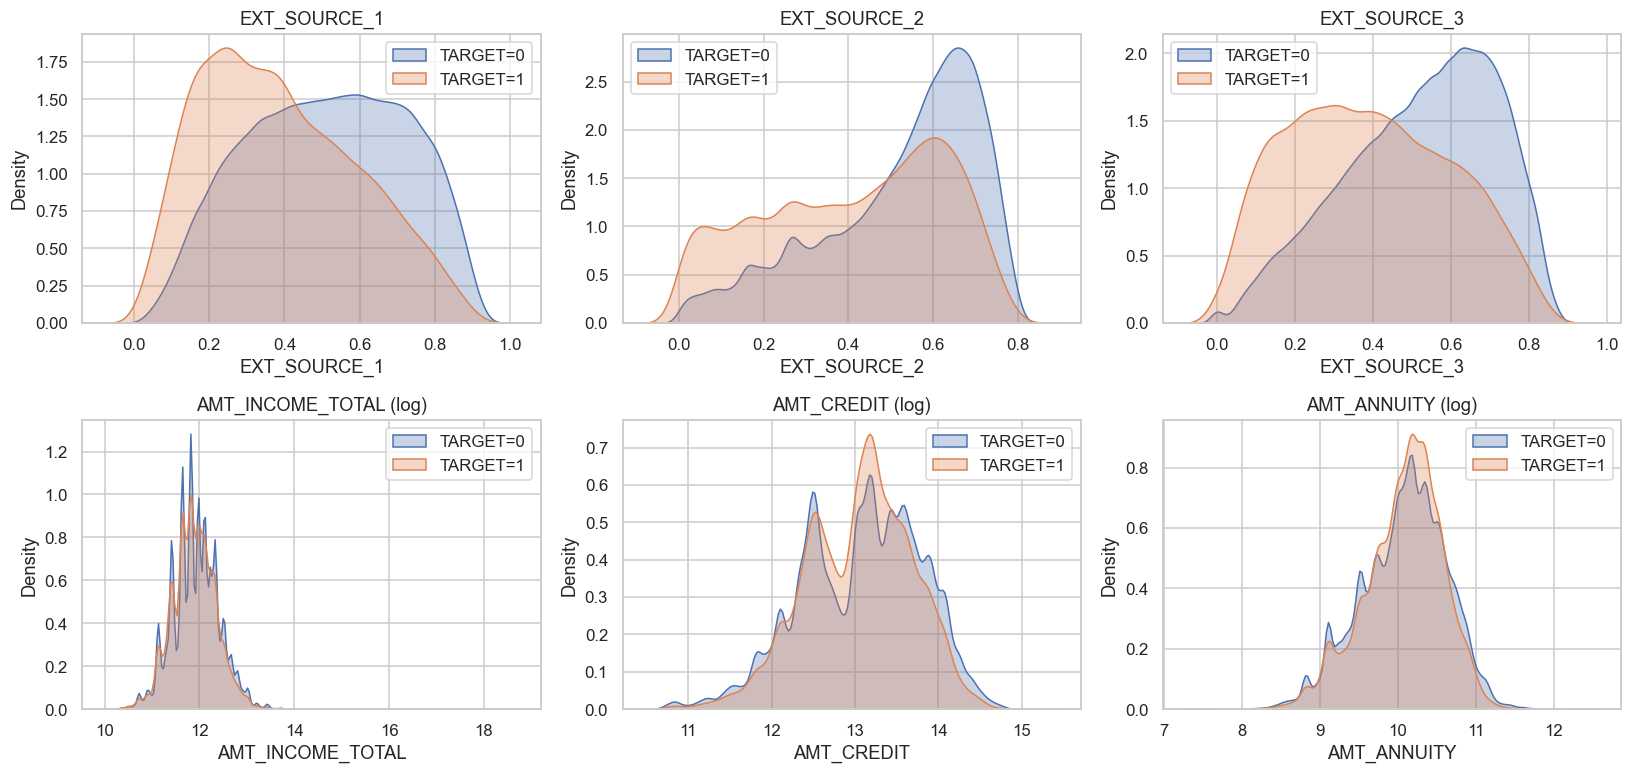

In [18]:


def plot_distributions(df, cols, target="TARGET", ncols=3, log_cols=()):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.6 * nrows))
    for ax, col in zip(np.ravel(axes), cols):
        for t in (0, 1):
            x = df.loc[df[target] == t, col].dropna()
            if col in log_cols:
                x = np.log1p(x.clip(lower=0))
            sns.kdeplot(x, ax=ax, label=f"TARGET={t}", fill=True, common_norm=False, alpha=0.3)
        ax.set_title(col + (" (log)" if col in log_cols else ""))
        ax.legend()
    for ax in np.ravel(axes)[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
        "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY"]
plot_distributions(train, cols, log_cols=("AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY"))

72 variables continues, 32 binaires


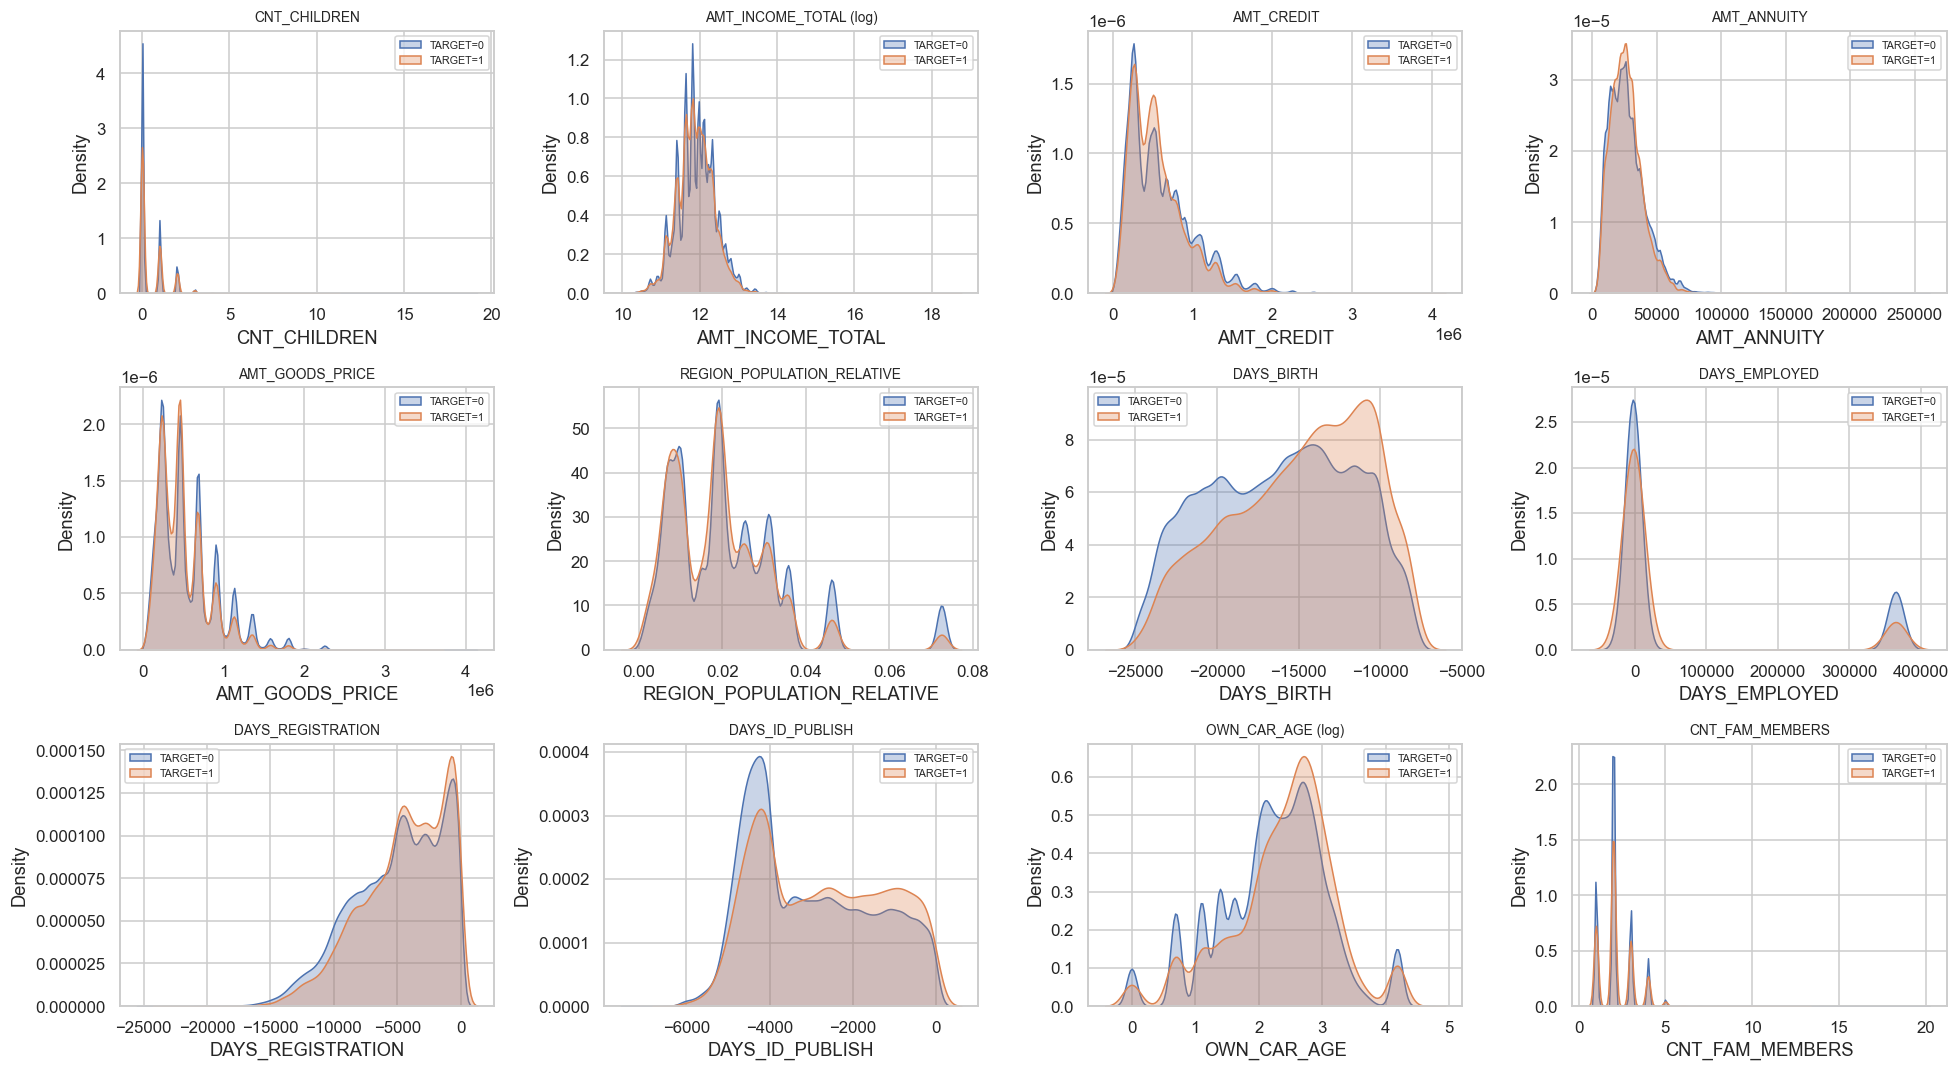

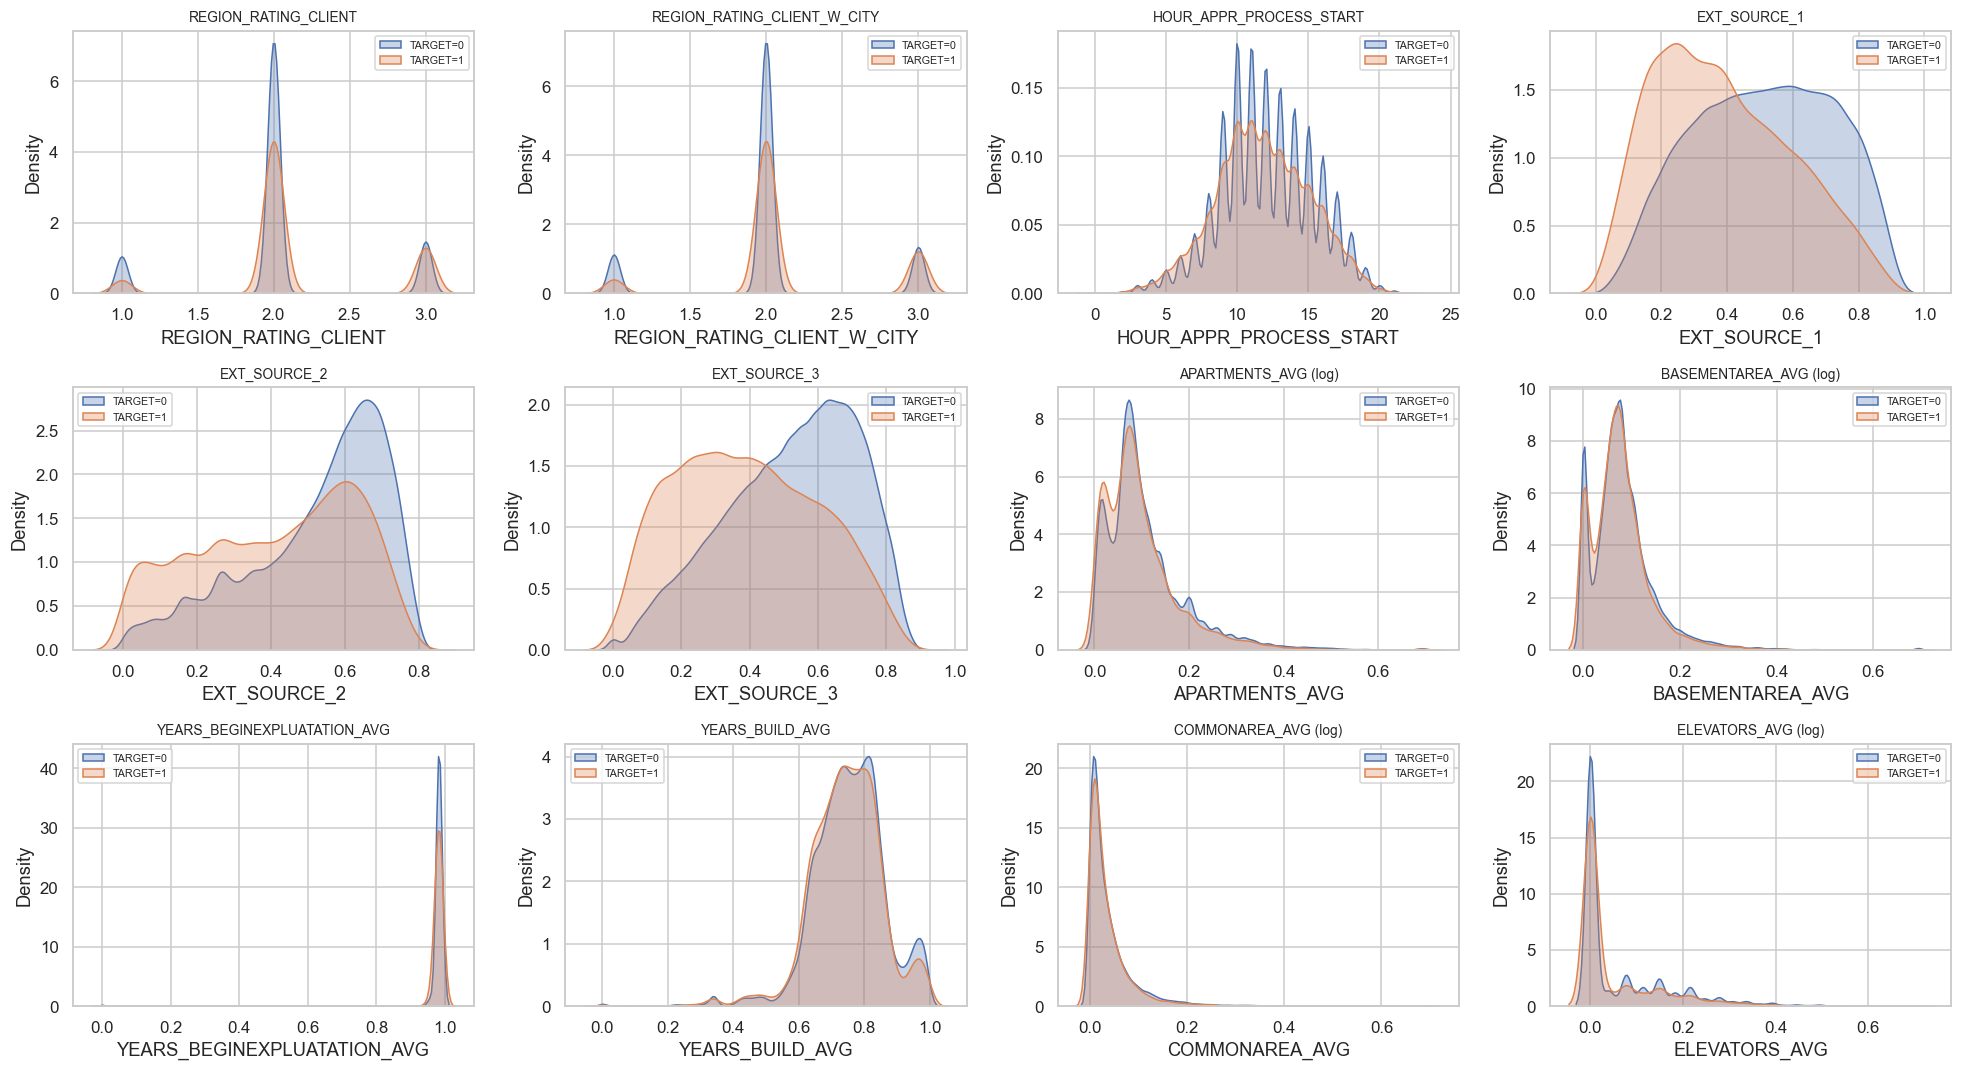

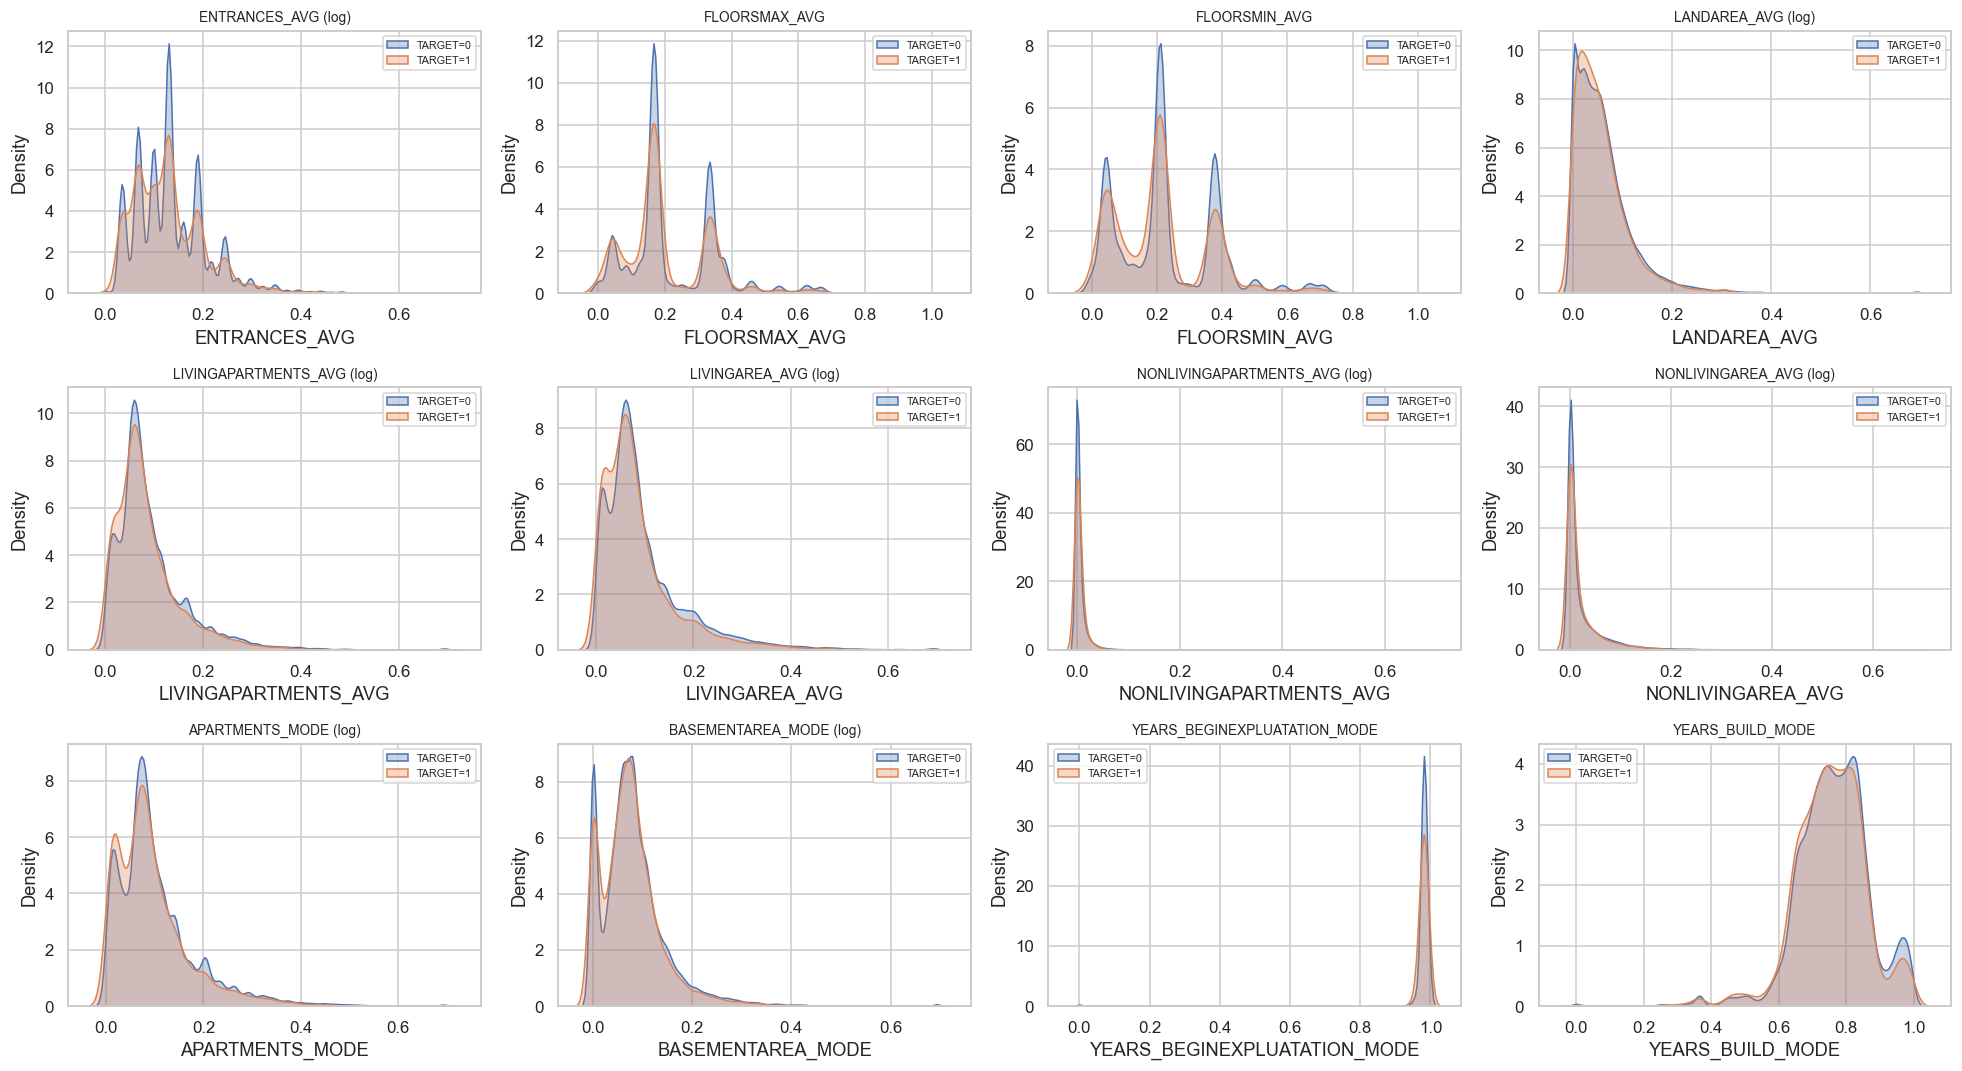

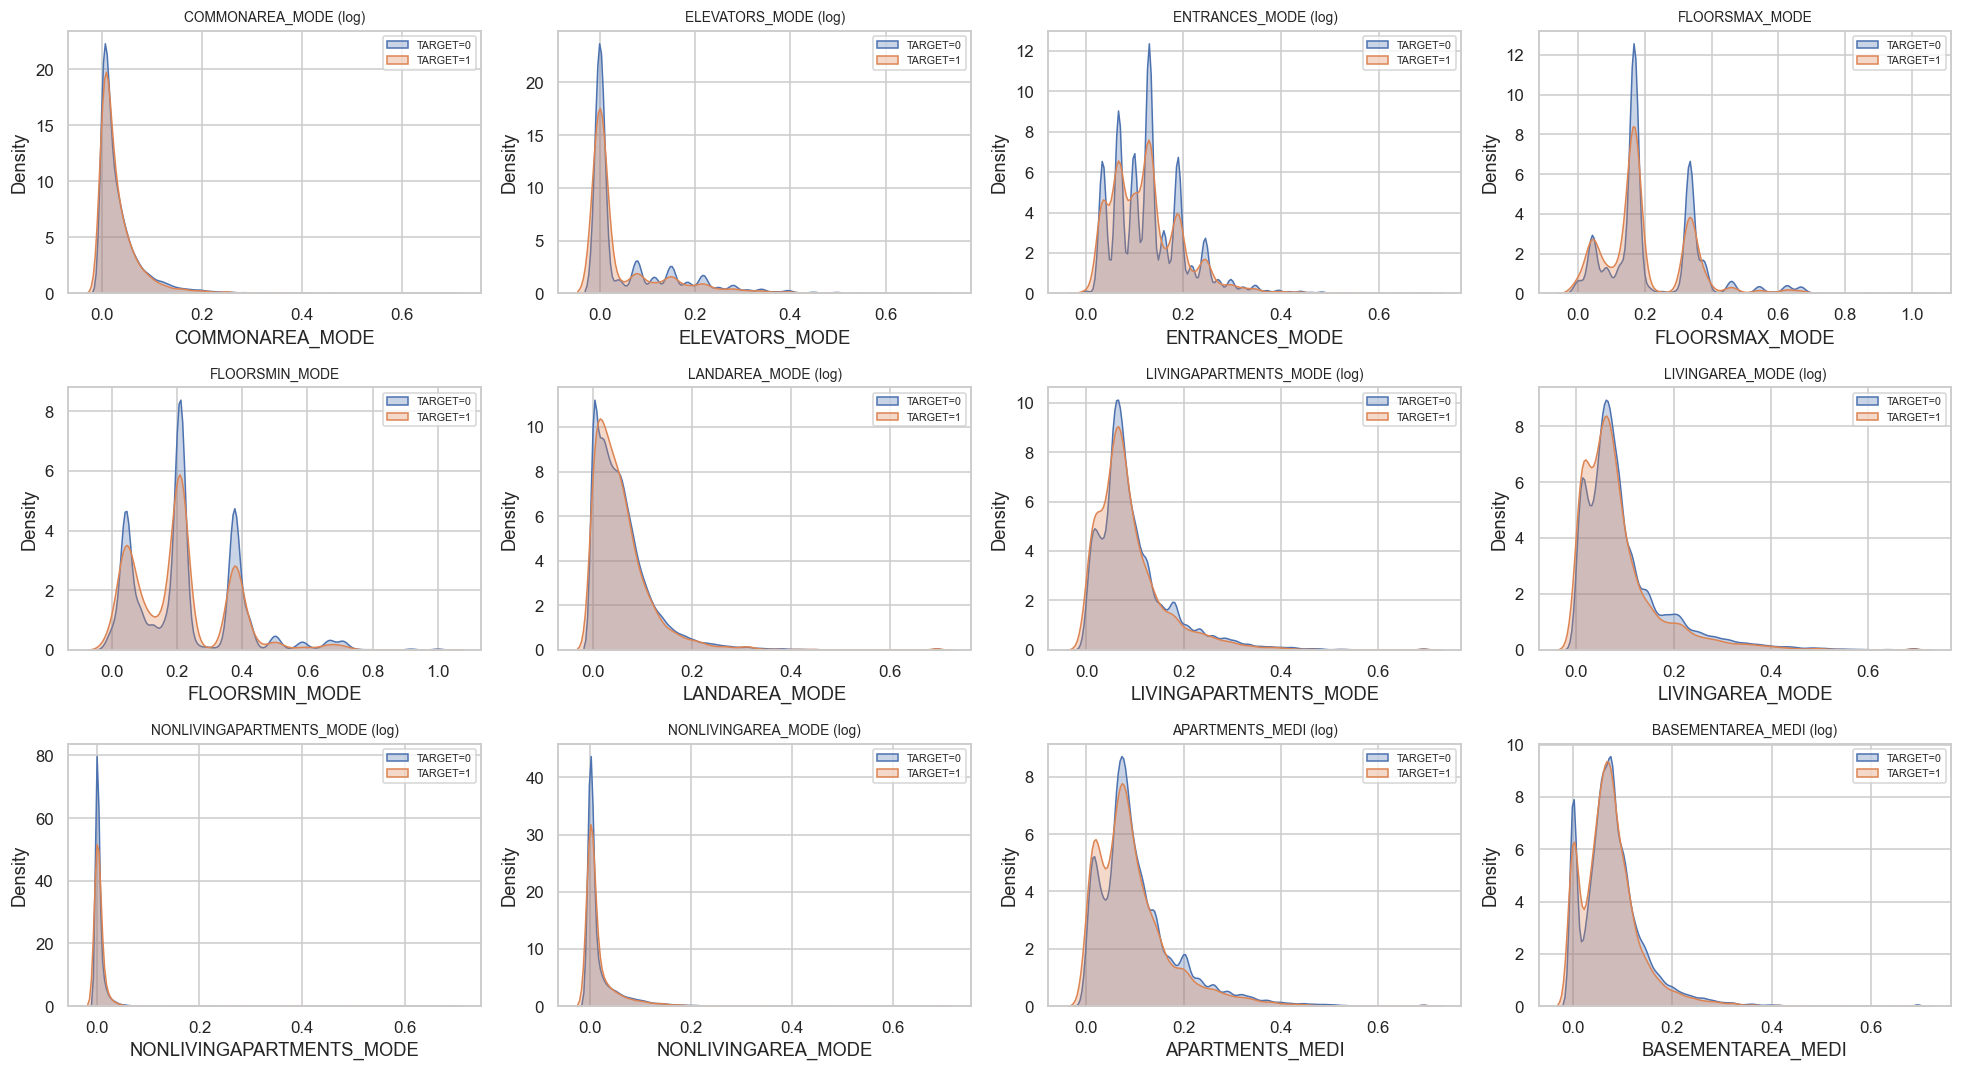

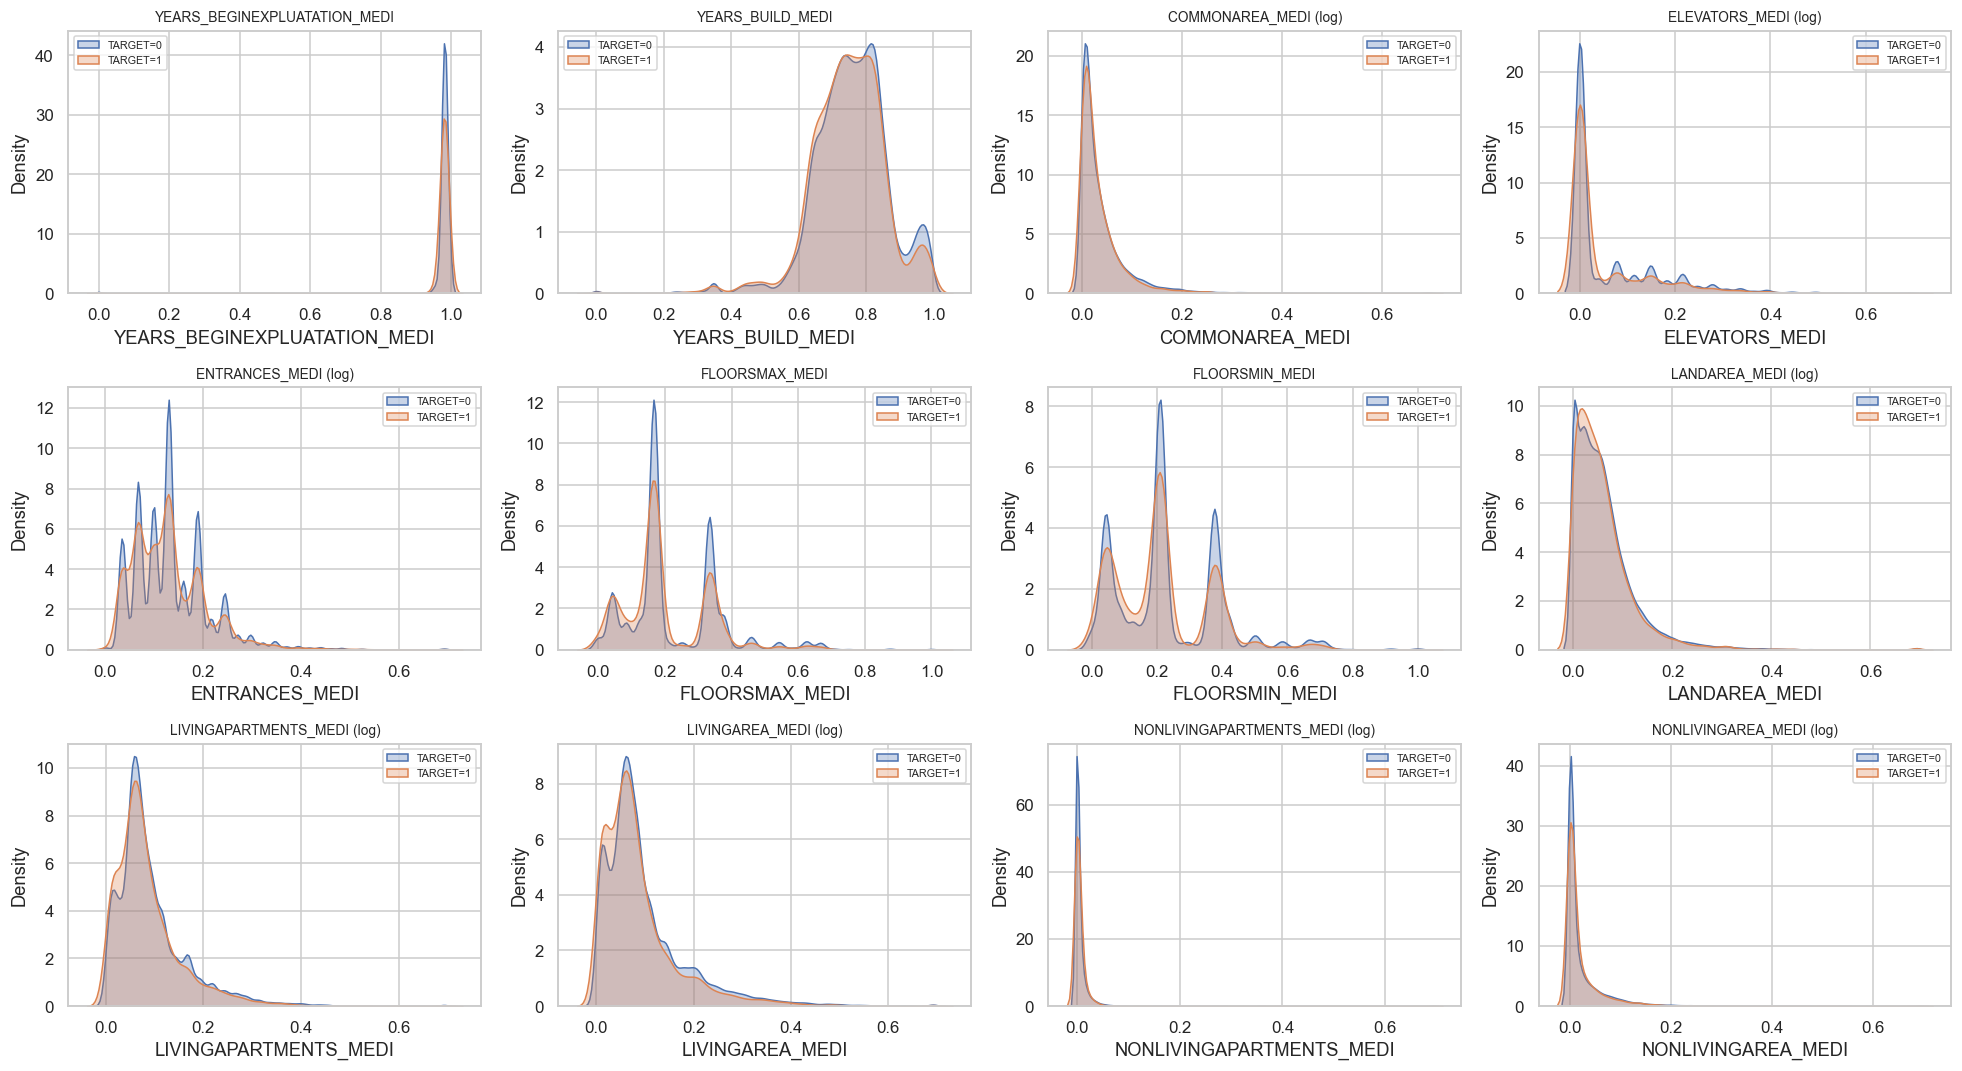

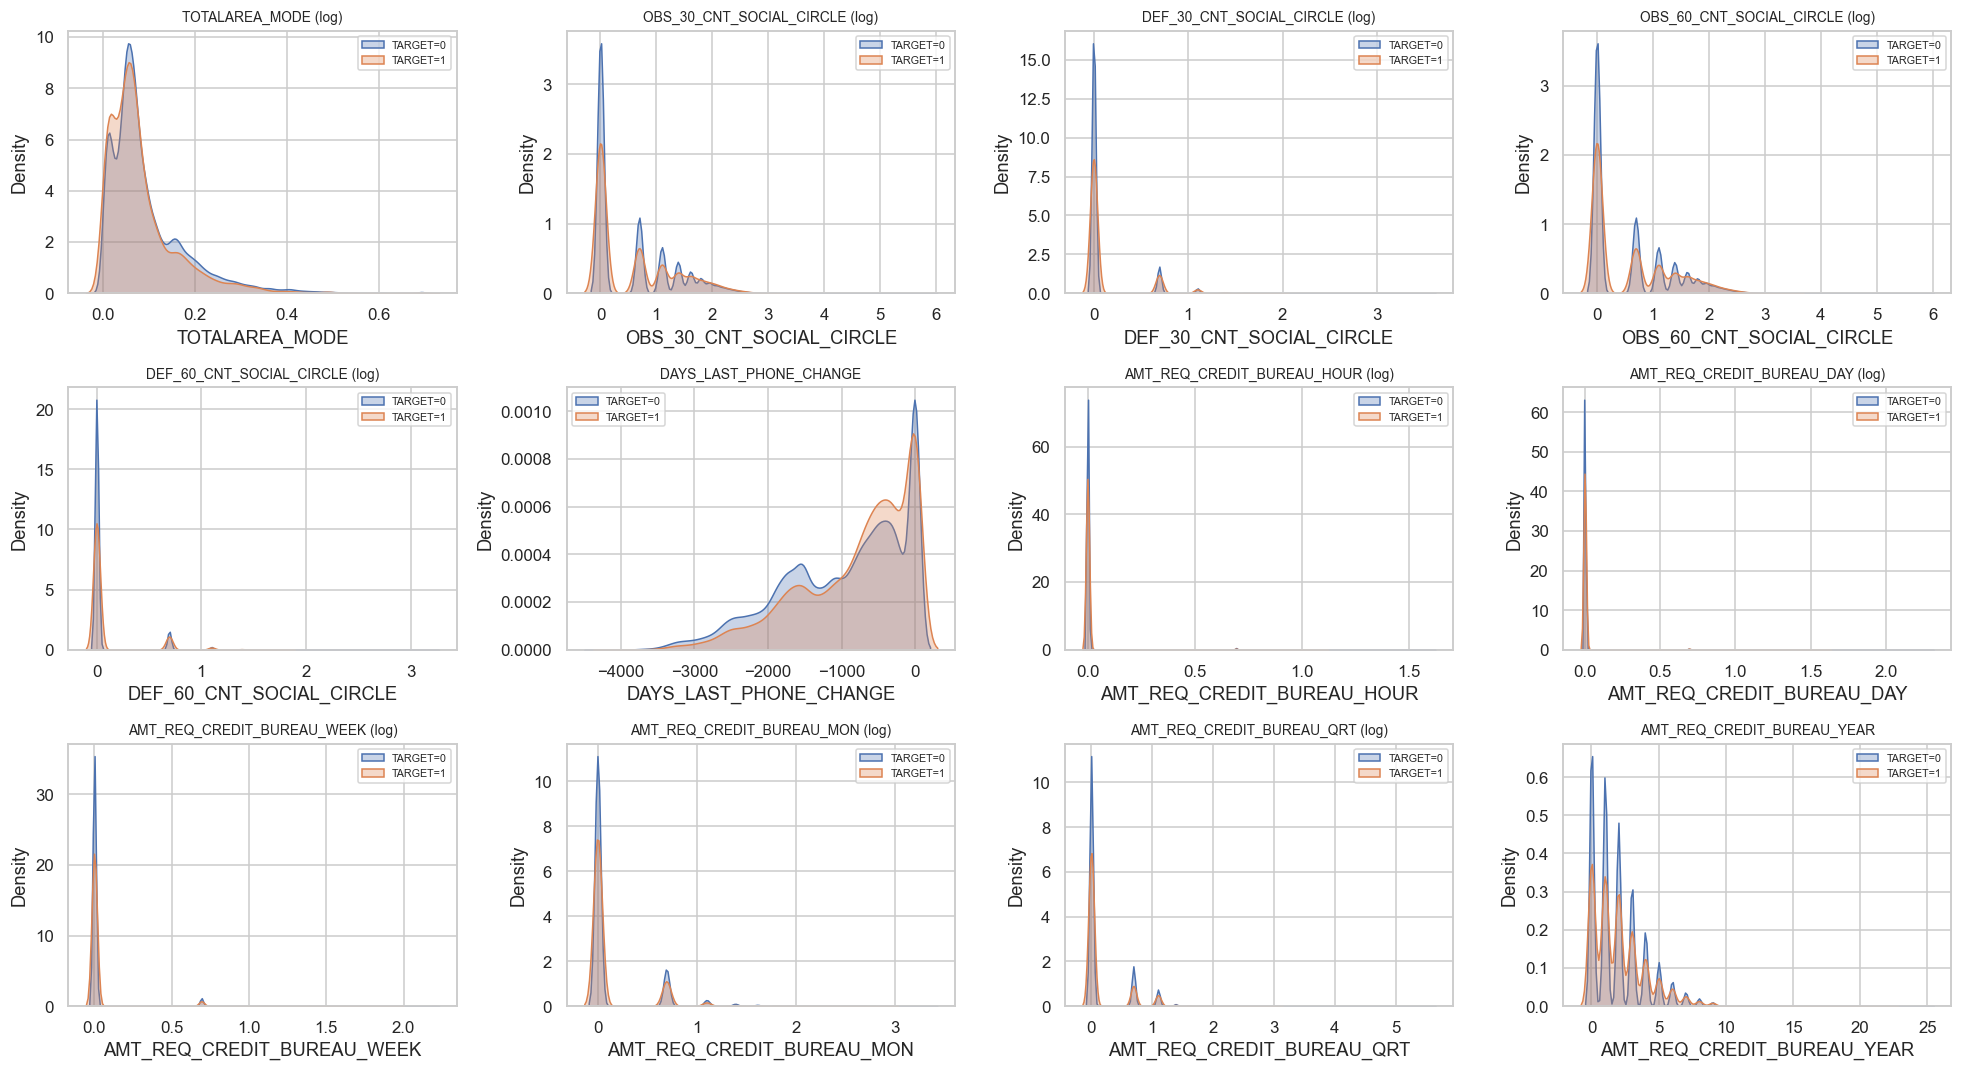

In [22]:
def plot_distributions(df, cols, target="TARGET", ncols=4, save_path=None):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.3 * nrows))
    for ax, col in zip(np.ravel(axes), cols):
        s = df[col].dropna()
        use_log = s.min() >= 0 and s.skew() > 2
        for t in (0, 1):
            x = df.loc[df[target] == t, col].dropna()
            x = np.log1p(x) if use_log else x
            if x.nunique() > 1:
                sns.kdeplot(x, ax=ax, label=f"TARGET={t}", fill=True,
                            common_norm=False, alpha=0.3)
        ax.set_title(col + (" (log)" if use_log else ""), fontsize=9)
        ax.legend(fontsize=7)
    for ax in np.ravel(axes)[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, bbox_inches="tight")
    plt.show()

num_cols = [c for c in train.select_dtypes(include="number").columns
            if c not in (TARGET, ID_COL)]
binary_cols = [c for c in num_cols if train[c].dropna().nunique() <= 2]
cont_cols = [c for c in num_cols if c not in binary_cols]
print(len(cont_cols), "variables continues,", len(binary_cols), "binaires")

for i in range(0, len(cont_cols), 12):
    plot_distributions(train, cont_cols[i:i + 12],
                       save_path=PATHS["figures"] / f"06_distributions_{i // 12 + 1}.png")



L'analyse des distributions, séparées selon la variable cible (`TARGET = 0` et `TARGET = 1`), poursuit trois objectifs. Premièrement, elle permet d'évaluer le **pouvoir discriminant** de chaque variable : lorsque les courbes des bons et des mauvais payeurs sont décalées, comme pour `EXT_SOURCE_1/2/3` où les scores faibles sont associés à un risque plus élevé de défaut, la variable apporte une information utile à la prédiction ; lorsqu'elles se superposent, comme pour `AMT_INCOME_TOTAL` ou `AMT_ANNUITY`, son effet isolé est faible. Deuxièmement, elle renseigne sur la **forme des données** (asymétrie, valeurs extrêmes, pics liés à des montants standards ou arrondis), ce qui guide les choix de traitement : médiane plutôt que moyenne pour l'imputation, transformation logarithmique pour les modèles linéaires, gestion des valeurs aberrantes. Troisièmement, elle oriente le **feature engineering** : une variable peu discriminante seule, comme les montants de crédit ou de revenu, peut le devenir une fois combinée sous forme de ratio. 

In [25]:
class ColumnCleaner(BaseEstimator, TransformerMixin):
    """Traite DAYS_EMPLOYED, retire l'identifiant et les colonnes trop incomplètes.
    La liste des colonnes à supprimer est apprise sur le TRAIN (fit)."""

    def __init__(self, threshold=0.50, keep=("EXT_SOURCE_1",), id_col=ID_COL):
        self.threshold, self.keep, self.id_col = threshold, keep, id_col

    def fit(self, X, y=None):
        miss = X.isna().mean()
        self.drop_cols_ = [c for c in miss[miss >= self.threshold].index
                           if c not in self.keep]
        self.feature_names_out_ = np.array(self._apply(X.iloc[:1]).columns, dtype=object)
        return self

    def transform(self, X):
        return self._apply(X)

    def _apply(self, X):
        X = X.copy()
        X["DAYS_EMPLOYED_ANOM"] = (X["DAYS_EMPLOYED"] == 365243).astype(int)
        X["DAYS_EMPLOYED"] = X["DAYS_EMPLOYED"].replace(365243, np.nan)
        return X.drop(columns=self.drop_cols_ + [self.id_col], errors="ignore")

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_out_

In [26]:

imputer = ColumnTransformer(
    [
        # numériques : médiane + indicateur de manque
        ("num", SimpleImputer(strategy="median", add_indicator=True),
         make_column_selector(dtype_include="number")),
        # catégorielles : modalité "Inconnu"
        ("cat", SimpleImputer(strategy="constant", fill_value="Inconnu"),
         make_column_selector(dtype_exclude="number")),
    ],
    verbose_feature_names_out=False,
)

prep = Pipeline([("clean", ColumnCleaner()), ("impute", imputer)])
prep.set_output(transform="pandas")

# --- apprentissage sur le train uniquement, puis application au test
X_train = prep.fit_transform(train.drop(columns=[TARGET]))
y_train = train[TARGET]
X_test = prep.transform(test)

print(X_train.shape, X_test.shape)
print("NaN restants :", X_train.isna().sum().sum(), "|", X_test.isna().sum().sum())
print("Colonnes supprimées :", prep.named_steps["clean"].drop_cols_)

# --- sauvegarde pour réutiliser le même pipeline plus tard
joblib.dump(prep, PATHS["models"] / "preprocessing.joblib")
# prep = joblib.load(PATHS["models"] / "preprocessing.joblib")

(307511, 106) (48744, 106)
NaN restants : 0 | 0
Colonnes supprimées : ['OWN_CAR_AGE', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG', 'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG', 'APARTMENTS_MODE', 'BASEMENTAREA_MODE', 'YEARS_BUILD_MODE', 'COMMONAREA_MODE', 'ELEVATORS_MODE', 'ENTRANCES_MODE', 'FLOORSMIN_MODE', 'LANDAREA_MODE', 'LIVINGAPARTMENTS_MODE', 'LIVINGAREA_MODE', 'NONLIVINGAPARTMENTS_MODE', 'NONLIVINGAREA_MODE', 'APARTMENTS_MEDI', 'BASEMENTAREA_MEDI', 'YEARS_BUILD_MEDI', 'COMMONAREA_MEDI', 'ELEVATORS_MEDI', 'ENTRANCES_MEDI', 'FLOORSMIN_MEDI', 'LANDAREA_MEDI', 'LIVINGAPARTMENTS_MEDI', 'LIVINGAREA_MEDI', 'NONLIVINGAPARTMENTS_MEDI', 'NONLIVINGAREA_MEDI', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE']


['C:\\Users\\Anna\\Documents\\M2 EQUADE\\Projet_personnel\\Home_credit_default_1\\Credit-Risk-Scoring\\models\\preprocessing.joblib']

Les variables dont le taux de valeurs manquantes dépasse 50 % ont été retirées, afin d’éviter qu’une majorité de valeurs soit issue de l’imputation, source de biais et de sous-estimation de la variance. EXT_SOURCE_1 a été conservée malgré un taux de 56 %, en raison de son fort pouvoir prédictif (Confirmer avecsa distribution). Pour les variables restantes, les valeurs numériques manquantes sont remplacées par la médiane, robuste aux distributions asymétriques, et complétées par un indicateur de manque afin de conserver l’information éventuellement portée par l’absence de valeur. Les variables catégorielles reçoivent une modalité « Inconnu ». 

In [27]:
from sklearn import set_config
set_config(display="diagram")

prep   # à mettre en dernière ligne de la cellule : affiche le schéma interactif

# sauvegarde pour repartir de ces données sans refaire l'imputation
X_train.assign(**{TARGET: y_train.values}).to_pickle(PATHS["interim"] / "train_imputed.pkl")
X_test.to_pickle(PATHS["interim"] / "test_imputed.pkl")

# pour recharger plus tard :
# train_imp = pd.read_pickle(PATHS["interim"] / "train_imputed.pkl")